# Ayudantía: Tópicos Avanzados

## Ayudantes 👾

- S1: Josefa Buch
  - [IZ*ONE - DAYDREAM](https://open.spotify.com/track/4qj6sQ5Y3tY4MIEEzqGLhT?si=ZOvY8Mt4TpOX0LELdN_6jQ&utm_source=copy-link)
- S2: Bastián Pérez
  - [Daft Punk - Aerodynamic](https://open.spotify.com/track/3H3cOQ6LBLSvmcaV7QkZEu)
- S3: Carlos Martel
  - [Chystemc - Mi Fe](https://open.spotify.com/track/6eP769s7qMxoxKe2pWyyDf)
- S4: André Angulo
  - [Canserbero - C'est La Mort](https://open.spotify.com/track/5j2P3w4A2urLfFldFCmYLZ?si=wgkZfIZ4Tt2p1iJC8ZahfA&utm_source=native-share-menu)
- S5: Juan Pablo Olivares
  - [Álvaro Díaz - Ramona Flowers](https://open.spotify.com/track/6cOjQjg8GRhLozpoyiqvfp?si=_g0W_kFjSZqrRfnaauD1vQ&utm_source=copy-link)


## Contenidos 📖

- Expresiones regulares (RegEx)
- Grafos: matriz de adyacencia vs. estructura nodal
- Recorridos: DFS y BFS (camino más corto en número de pasos)
- NumPy + Pandas

## Contexto

Es lunes, 07:58 y el Metro de Santiago colapsó. 🥲 El DCC fue contratado para crear **DCCMetro**, un sistema que:

1. **Lee** los registros crudos de los torniquetes (RegEx).
2. **Calcula rutas** con la menor cantidad de estaciones, incluso con estaciones cerradas (grafo con matriz de adyacencia).
3. **Saca** a un ayudante perdido de un túnel de mantención (grafo con estructura nodal sobre una matriz).
4. **Analiza** un mes de viajes para entender la experiencia de los pasajeros (NumPy + Pandas).

> ⚠️ La red de metro y las tarifas de esta ayudantía son **simplificadas/ficticias**: no corresponden al mapa ni a los precios reales.

In [ ]:
import re
from pathlib import Path
from collections import deque, namedtuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Validacion = namedtuple(
    "Validacion",
    ["fecha", "hora", "tarjeta", "estacion", "linea", "monto"],
)

# Parte 1: Expresiones regulares 🔎

## Repaso 📚

Una **expresión regular** describe un *patrón* de texto. Cada carácter normal hace *match* consigo mismo, pero los **meta-caracteres** `. ^ $ * + ? { } [ ] \ | ( )` tienen significados especiales.

### Meta-caracteres y clases

| Símbolo | Significado | Ejemplo | Hace *match* con |
|---|---|---|---|
| `.` | Cualquier carácter (menos salto de línea) | `a.c` | `abc`, `a7c` |
| `[abc]` | Uno de los caracteres de la clase | `[aeiou]` | `a`, `e` |
| `[a-z]` | Rango de caracteres | `[0-9]` | `4` |
| `[^abc]` | Cualquiera **excepto** los de la clase | `[^0-9]` | `x`, `-` |
| `\d` / `\D` | Dígito / no dígito | `\d\d` | `42` |
| `\s` / `\S` | Espacio en blanco / no espacio | `a\sb` | `a b` |
| `\w` / `\W` | Alfanumérico o `_` / lo contrario | `\w+` | `alumno_1` |
| `\` | "Escapa" un meta-carácter | `\$\d+` | `$870` |

### Cuantificadores, aserciones y grupos

| Símbolo | Significado | Ejemplo | Hace *match* con |
|---|---|---|---|
| `+` | 1 o más veces | `ab+c` | `abc`, `abbbc` |
| `*` | 0 o más veces | `ab*c` | `ac`, `abbc` |
| `?` | 0 o 1 vez (opcional) | `colou?r` | `color`, `colour` |
| `{m}` / `{m,n}` | Exactamente `m` / entre `m` y `n` veces | `\d{2,3}` | `12`, `123` |
| `^` / `$` | Inicio / término del *string* | `^4tt` | `4ttab...` |
| `A\|B` | `A` o `B` | `L1\|L2` | `L1`, `L2` |
| `( )` | Grupo de captura | `(ab)+` | `abab` |
| `(?P<nombre> )` | Grupo de captura **con nombre** | `(?P<anio>\d{4})` | `2026` → `anio` |
| `(?: )` | Grupo **sin** captura (solo agrupa) | `(?:0[1-9]\|1[0-2])` | `07`, `12` |

### Funciones del módulo `re`

| Función | Modo de uso | ¿Qué busca? | Retorna |
|---|---|---|---|
| `re.match` | `re.match(patron, s)` | Patrón **al inicio** de `s` | `Match` o `None` |
| `re.fullmatch` | `re.fullmatch(patron, s)` | Que **todo** `s` cumpla el patrón | `Match` o `None` |
| `re.search` | `re.search(patron, s)` | **Primera** aparición en cualquier parte | `Match` o `None` |
| `re.findall` | `re.findall(patron, s)` | **Todas** las apariciones | `list` |
| `re.sub` | `re.sub(patron, reemplazo, s)` | Reemplaza cada aparición | `str` nuevo |
| `re.split` | `re.split(patron, s)` | Separa `s` donde aparece el patrón | `list` |

Con un objeto `Match` podemos usar `m.group()` (todo el *match*), `m.group(1)` o `m.group("nombre")` (un grupo) y `m.groupdict()` (diccionario con los grupos nombrados).

> 💡 Escribe los patrones como *raw strings* (`r"\d+"`) para evitar el `SyntaxWarning: invalid escape sequence`.

## Caso: Torniquetes de DCCMetro 🚇

Cada vez que alguien pasa su tarjeta, el torniquete escribe una línea en `data/validaciones.txt` con este formato:

```text
YYYY-MM-DD HH:MM | BIP-XXXXXXXX | Nombre Estación (Línea) | $monto
```

Por ejemplo:

```text
2026-11-03 07:42 | BIP-48213907 | Los Héroes (L1) | $870
```

Reglas de una línea **válida**:

- Fecha real en formato `YYYY-MM-DD` (mes `01`–`12`, día `01`–`31`).
- Hora en formato 24 h `HH:MM` (`00:00` a `23:59`).
- Tarjeta: `BIP-` seguido de **exactamente 8 dígitos**.
- Estación: una o más palabras con letras (¡incluye tildes y ñ!) separadas por un espacio.
- Línea entre paréntesis: `L1` a `L6`, o `L4A`.
- Monto: signo `$` seguido de dígitos.
- Puede haber **espacios extra** al inicio, al final y alrededor de los `|`.

Los lectores están viejos, así que hay líneas con fechas imposibles, tarjetas cortas, separadores faltantes, líneas que no existen, estaciones vacías y basura.

## 1.1 Validación y extracción

Implementa `extraer_validacion(linea)` que retorne una `Validacion` (con `monto` como `int` y el nombre de la estación **sin** espacios sobrantes) o `None` si la línea es inválida. Luego implementa `leer_validaciones(ruta)`.

Pistas:

- `re.fullmatch` valida la línea completa.
- Los **grupos nombrados** `(?P<nombre>...)` permiten usar `match.group("nombre")` o `match.groupdict()`.
- Para alternativas sin capturar usa `(?:...)`, por ejemplo `(?:0[1-9]|1[0-2])` para el mes.
- Cuidado con caracteres especiales: `|`, `$`, `(` y `)` deben escaparse.

In [ ]:
def extraer_validacion(linea: str) -> Validacion | None:
    """
    Recibe una linea y devuelve una Validacion si el formato es valido.
    Si no lo es, devuelve None.
    """
    # TODO: COMPLETAR
    raise NotImplementedError


def leer_validaciones(ruta: Path) -> list[Validacion]:
    """
    Lee un archivo y retorna solo las validaciones correctas.
    """
    # TODO: COMPLETAR
    raise NotImplementedError

In [ ]:
PATH_VALIDACIONES = Path("data", "validaciones.txt")
validaciones = leer_validaciones(PATH_VALIDACIONES)

print(f"Validaciones correctas: {len(validaciones)}\n")
for v in validaciones:
    print(v)

Validaciones correctas: 7

Validacion(fecha='2026-11-03', hora='07:42', tarjeta='BIP-48213907', estacion='Los Héroes', linea='L1', monto=870)
Validacion(fecha='2026-11-03', hora='07:45', tarjeta='BIP-10293847', estacion='Universidad de Chile', linea='L3', monto=870)
Validacion(fecha='2026-11-03', hora='08:15', tarjeta='BIP-77001122', estacion='Tobalaba', linea='L4', monto=260)
Validacion(fecha='2026-11-03', hora='12:40', tarjeta='BIP-20202020', estacion='Vicuña Mackenna', linea='L4A', monto=790)
Validacion(fecha='2026-11-03', hora='18:47', tarjeta='BIP-31415926', estacion='Plaza Egaña', linea='L3', monto=390)
Validacion(fecha='2026-11-03', hora='19:02', tarjeta='BIP-27182818', estacion='Irarrázaval', linea='L5', monto=870)
Validacion(fecha='2026-11-03', hora='21:58', tarjeta='BIP-11235813', estacion='Plaza de Armas', linea='L3', monto=720)


## 1.2 Anonimización de tarjetas 🕵️

Por la ley de protección de datos, antes de compartir los registros hay que **ocultar los primeros 4 dígitos** de cada tarjeta. Implementa `anonimizar(texto)` usando `re.sub` y un grupo de captura, de modo que:

```text
BIP-48213907  ->  BIP-****3907
```

La función debe funcionar sobre **cualquier texto** (no solo líneas válidas): reemplaza todas las tarjetas que encuentre.

Pista: en el reemplazo puedes referenciar un grupo con `\1`.

`BONUS`: usando `re.findall`, cuenta cuántas veces aparece cada línea de metro (`L1`, `L2`, ...) en el archivo **completo** (incluyendo líneas inválidas). ¿Por qué el resultado es distinto a contar solo validaciones correctas?

In [ ]:
def anonimizar(texto: str) -> str:
    # TODO: COMPLETAR
    raise NotImplementedError

In [ ]:
texto_crudo = PATH_VALIDACIONES.read_text(encoding="utf-8")
print(anonimizar(texto_crudo))

2026-11-03 07:42 | BIP-****3907 | Los Héroes (L1) | $870
   2026-11-03 07:45   |  BIP-****3847 |   Universidad de Chile (L3)  |  $870
2026-13-03 08:01 | BIP-****2340 | Baquedano (L5) | $870
2026-11-03 25:10 | BIP-****2340 | Baquedano (L5) | $870
2026-11-03 08:15 | BIP-****1122 | Tobalaba (L4) | $260
2026-11-03 08:20 | BIP-1234 | Salvador (L1) | $870
2026-11-03 08:22 BIP-****8899 | Ñuñoa (L3) | $870
2026-11-03 08:30 | BIP-****8899 | Ñuñoa (L9) | $870

2026-11-03 12:40 | BIP-****2020 | Vicuña Mackenna (L4A) | $790
2026-11-03 13:05 | BIP-****7263 | Santa Ana (L2) | 790
2026-11-03 13:10 | BIP-****7263 |  (L2) | $790
2026-11-03 18:47 | BIP-****5926 | Plaza Egaña (L3) | $390
ERROR: lector desconectado en estacion Baquedano
2026-11-03 19:02 | BIP-****2818 | Irarrázaval (L5) | $870
2026-11-32 19:30 | BIP-****2818 | Irarrázaval (L5) | $870
2026-11-03 21:58 | BIP-****5813 | Plaza de Armas (L3) | $720



In [ ]:
"""COMPLETAR"""

Archivo completo:    Counter({'L3': 4, 'L5': 4, 'L1': 2, 'L2': 2, 'L4': 1, 'L9': 1, 'L4A': 1})
Solo validaciones:   Counter({'L3': 3, 'L1': 1, 'L4': 1, 'L4A': 1, 'L5': 1})


# Parte 2: Grafos 🕸️

## Repaso 📚

Un **grafo** es un conjunto de **vértices** (nodos) y **aristas** (relaciones entre ellos). Puede ser:

- **No dirigido**: si `A` se conecta con `B`, entonces `B` se conecta con `A` (amistad en Facebook, líneas de metro).
- **Dirigido**: la relación tiene sentido; `A → B` no implica `B → A` (seguir a alguien en Instagram).

### Representaciones

| Representación | ¿Cómo se ve en Python? | ¿Hay arista `x → y`? | Vecinos de `x` | Ventaja | Desventaja |
|---|---|---|---|---|---|
| **Con nodos** | Clase `Nodo` con atributo `self.vecinos = []` | Revisar si `y in x.vecinos` | `x.vecinos` | Natural para modelar objetos | Para encontrar un nodo hay que recorrer el grafo |
| **Lista de adyacencia** | `dict`: `{1: [2], 2: [1, 3], ...}` | `y in grafo[x]` | `grafo[x]` | Rápido acceder a un vértice; ocupa poca memoria | Para saber si hay arista `x → y` hay que buscar en la lista de `x` |
| **Matriz de adyacencia** | Lista de listas $N \times N$ con `0`/`1` | `matriz[x][y] == 1` | Recorrer la fila `x` buscando `1` | Saber si hay arista es inmediato | Ocupa $N \times N$, aunque haya pocas aristas |

> En la matriz de un grafo **no dirigido** se cumple `matriz[i][j] == matriz[j][i]` (es simétrica).

### Recorridos

| | **BFS** (*Breadth-first search*) | **DFS** (*Depth-first search*) |
|---|---|---|
| Estructura | **Cola**: `deque` con `append` + `popleft` | **Stack**: `list` con `append` + `pop`, o **recursión** |
| Orden de visita | Por niveles: primero los que están a 1 arista, luego a 2, ... | Se va lo más profundo posible por una rama y luego retrocede |
| Sirve para... | Camino con la **menor cantidad de aristas** | Saber si **existe** un camino / qué nodos son alcanzables |
| ¿Camino más corto? | ✔ Sí (si todas las aristas "pesan" lo mismo) | ✘ No necesariamente |

**Clave en grafos (a diferencia de árboles):** pueden existir **ciclos**, así que siempre hay que llevar registro de los **visitados**; si no, el recorrido puede no terminar nunca.

**Para reconstruir un camino:** guarda para cada nodo desde cuál llegaste (`anterior` / `padres`). Al encontrar el destino, sigue esos punteros hacia atrás y da vuelta la lista.

## Parte 2A: La red de DCCMetro (matriz de adyacencia)

La red simplificada tiene 14 estaciones. Cada estación es un **índice** y la conexión entre estaciones se guarda en `MATRIZ`, una lista de listas simétrica (el grafo es **no dirigido**: los trenes van en ambos sentidos).

In [ ]:
ESTACIONES = [
    "Los Héroes", "La Moneda", "Universidad de Chile", "Santa Lucía",
    "Baquedano", "Salvador", "Tobalaba", "Santa Ana", "Puente Cal y Canto",
    "Plaza de Armas", "Bellas Artes", "Irarrázaval", "Ñuñoa", "Plaza Egaña",
]
INDICE = {nombre: i for i, nombre in enumerate(ESTACIONES)}

CONEXIONES = [
    (0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6),     # "L1"
    (0, 7), (7, 8),                                     # "L2"
    (8, 9), (9, 2), (2, 11), (11, 12), (12, 13),        # "L3"
    (7, 9), (9, 10), (10, 4), (4, 11),                  # "L5"
    (6, 13),                                            # "L4"
]

n = len(ESTACIONES)
MATRIZ = [[0] * n for _ in range(n)]
for i, j in CONEXIONES:
    MATRIZ[i][j] = 1
    MATRIZ[j][i] = 1

print(np.array(MATRIZ))

[[0 1 0 0 0 0 0 1 0 0 0 0 0 0]
 [1 0 1 0 0 0 0 0 0 0 0 0 0 0]
 [0 1 0 1 0 0 0 0 0 1 0 1 0 0]
 [0 0 1 0 1 0 0 0 0 0 0 0 0 0]
 [0 0 0 1 0 1 0 0 0 0 1 1 0 0]
 [0 0 0 0 1 0 1 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 0 0 0 0 0 0 0 1]
 [1 0 0 0 0 0 0 0 1 1 0 0 0 0]
 [0 0 0 0 0 0 0 1 0 1 0 0 0 0]
 [0 0 1 0 0 0 0 1 1 0 1 0 0 0]
 [0 0 0 0 1 0 0 0 0 1 0 0 0 0]
 [0 0 1 0 1 0 0 0 0 0 0 0 1 0]
 [0 0 0 0 0 0 0 0 0 0 0 1 0 1]
 [0 0 0 0 0 0 1 0 0 0 0 0 1 0]]


## 2.1 Vecinos y grado

- Implementa `vecinos(matriz, i)` que retorne la lista de **índices** conectados con la estación `i`.
- Usando NumPy, calcula el **grado** de cada estación (cantidad de conexiones) e indica cuál es la estación con más conexiones.

Pista: `np.array(MATRIZ).sum(axis=1)` y `np.argmax`.

In [ ]:
def vecinos(matriz: list[list[int]], i: int) -> list[int]:
    # TODO: COMPLETAR
    raise NotImplementedError

In [ ]:
print("Vecinos de Baquedano:", [ESTACIONES[j] for j in vecinos(MATRIZ, INDICE["Baquedano"])])

"""COMPLETAR: grado de cada estación y estación más conectada"""

Vecinos de Baquedano: ['Santa Lucía', 'Salvador', 'Bellas Artes', 'Irarrázaval']
Grados: [2 2 4 2 4 2 2 3 2 4 2 3 2 2]
Estación más conectada: Universidad de Chile (4 conexiones)


## 2.2 DFS: ¿a dónde puedo llegar si cierran estaciones? 🚧

Por manifestaciones, a veces se cierran estaciones completas: no se puede **entrar, salir ni pasar** por ellas.

Implementa `dfs_alcanzables(matriz, origen, cerradas)` de forma **iterativa con una pila**, que retorne el conjunto de índices alcanzables desde `origen` sin pasar por estaciones cerradas. Si `origen` está cerrada, retorna un conjunto vacío.

> Aquí no nos importa el largo del camino, solo **si** se llega. Por eso DFS es suficiente.

In [ ]:
def dfs_alcanzables(matriz: list[list[int]], origen: int,
                    cerradas: set[int] = frozenset()) -> set[int]:
    # TODO: COMPLETAR
    raise NotImplementedError

In [ ]:
def nombres(indices):
    return sorted(ESTACIONES[i] for i in indices)

origen = INDICE["Los Héroes"]
print("Sin cierres:", len(dfs_alcanzables(MATRIZ, origen)), "estaciones alcanzables")

cerradas = {INDICE["Universidad de Chile"], INDICE["Baquedano"]}
alcanzables = dfs_alcanzables(MATRIZ, origen, cerradas)
print("Cerrando U. de Chile y Baquedano:", nombres(alcanzables))

Sin cierres: 14 estaciones alcanzables
Cerrando U. de Chile y Baquedano: ['Bellas Artes', 'La Moneda', 'Los Héroes', 'Plaza de Armas', 'Puente Cal y Canto', 'Santa Ana']


## 2.3 BFS: ruta con la menor cantidad de estaciones 🏃

Implementa `ruta_mas_corta(matriz, origen, destino, cerradas)` que retorne la **lista de índices** del camino con menos estaciones (incluyendo ambos extremos), o `None` si no existe.

Pistas:

- Usa `deque` como cola y un diccionario `padres` que guarde desde dónde llegaste a cada estación (también sirve como conjunto de visitados).
- Cuando sacas `destino` de la cola, reconstruye el camino siguiendo `padres` hacia atrás.

Preguntas:

- ¿Por qué BFS garantiza el camino con menos estaciones y DFS no?
- ¿Qué cambiaría si cada tramo tuviera un **tiempo** distinto? (spoiler: BFS ya no basta 👀 → Dijkstra)

In [ ]:
def ruta_mas_corta(matriz: list[list[int]], origen: int, destino: int,
                   cerradas: set[int] = frozenset()) -> list[int] | None:
    # TODO: COMPLETAR
    raise NotImplementedError

In [ ]:
def mostrar_ruta(origen, destino, cerradas_nombres=()):
    cerradas = {INDICE[e] for e in cerradas_nombres}
    ruta = ruta_mas_corta(MATRIZ, INDICE[origen], INDICE[destino], cerradas)
    titulo = f"{origen} -> {destino}" + (f" | cerradas: {list(cerradas_nombres)}" if cerradas else "")
    if ruta is None:
        print(f"{titulo}\n   Sin ruta posible 😢\n")
    else:
        print(f"{titulo}\n   {len(ruta) - 1} tramos: " + " → ".join(ESTACIONES[i] for i in ruta) + "\n")

mostrar_ruta("Los Héroes", "Plaza Egaña")
mostrar_ruta("Los Héroes", "Plaza Egaña", ["Universidad de Chile"])
mostrar_ruta("Los Héroes", "Plaza Egaña", ["Universidad de Chile", "Baquedano"])
mostrar_ruta("Santa Ana", "Santa Ana")

Los Héroes -> Plaza Egaña
   5 tramos: Los Héroes → La Moneda → Universidad de Chile → Irarrázaval → Ñuñoa → Plaza Egaña

Los Héroes -> Plaza Egaña | cerradas: ['Universidad de Chile']
   7 tramos: Los Héroes → Santa Ana → Plaza de Armas → Bellas Artes → Baquedano → Salvador → Tobalaba → Plaza Egaña

Los Héroes -> Plaza Egaña | cerradas: ['Universidad de Chile', 'Baquedano']
   Sin ruta posible 😢

Santa Ana -> Santa Ana
   0 tramos: Santa Ana



## Parte 2B: Perdido en el túnel (estructura nodal) 🔦

Un ayudante entró a un túnel de mantención y quedó atrapado. El plano del túnel está en `data/laberinto.txt`:

- `S`: posición del ayudante (inicio)
- `E`: salida
- `#`: muro
- `.`: pasillo libre

Solo se puede mover **arriba, abajo, izquierda o derecha** (no en diagonal).

Esta vez **no** usaremos una matriz de adyacencia (¡sería de $V \times V$ con casi puros ceros!). En vez de eso, transformaremos cada casilla libre en un objeto `Celda` con su propia lista de `vecinos`.

In [ ]:
def leer_laberinto(ruta: Path) -> list[str]:
    with open(ruta, encoding="utf-8") as archivo:
        return [linea.rstrip("\n") for linea in archivo if linea.strip()]


def dibujar(laberinto: list[str], camino=None) -> None:
    """Imprime el laberinto marcando con * las celdas del camino."""
    grilla = [list(fila) for fila in laberinto]
    for celda in camino or []:
        if grilla[celda.fila][celda.col] == ".":
            grilla[celda.fila][celda.col] = "*"
    for fila in grilla:
        print(" ".join(fila))


LABERINTO = leer_laberinto(Path("data", "laberinto.txt"))
dibujar(LABERINTO)

S . . . . . . . .
. # # # # # # # .
. # . . . . . # .
. # . # # # . # .
. . . # E . . # .
# # . # # # # # .
. . . . . . . . .


## 2.4 Construcción del grafo nodal

Completa `construir_grafo_laberinto(laberinto)`, que debe:

1. Crear una `Celda` por cada casilla que **no** sea muro y guardarla en un diccionario `{(fila, col): Celda}`.
2. Conectar cada celda con sus vecinas libres usando `MOVIMIENTOS` (respeta ese orden: derecha, abajo, izquierda, arriba).
3. Retornar `(celdas, inicio, fin)`.

Pista: hazlo en **dos pasadas**: primero crea todas las celdas y después conéctalas. ¿Por qué no se puede en una sola pasada?

In [ ]:
MOVIMIENTOS = [(0, 1), (1, 0), (0, -1), (-1, 0)]  # derecha, abajo, izquierda, arriba


class Celda:
    def __init__(self, fila: int, col: int, tipo: str):
        self.fila = fila
        self.col = col
        self.tipo = tipo
        self.vecinos: list[Celda] = []

    def agregar_vecino(self, celda: "Celda") -> None:
        self.vecinos.append(celda)

    def __repr__(self):
        return f"({self.fila}, {self.col})"


def construir_grafo_laberinto(laberinto: list[str]) -> tuple[dict, Celda, Celda]:
    # TODO: COMPLETAR
    raise NotImplementedError

In [ ]:
celdas, inicio, fin = construir_grafo_laberinto(LABERINTO)

print(f"Celdas libres: {len(celdas)}")
print(f"Inicio: {inicio} | Fin: {fin}")
print(f"Vecinos de (0, 0): {celdas[(0, 0)].vecinos}")
print(f"Vecinos de (4, 2): {celdas[(4, 2)].vecinos}")

Celdas libres: 40
Inicio: (0, 0) | Fin: (4, 4)
Vecinos de (0, 0): [(0, 1), (1, 0)]
Vecinos de (4, 2): [(5, 2), (4, 1), (3, 2)]


## 2.5 DFS: salir como sea

Implementa `dfs_camino(inicio, fin)` de forma **recursiva** (backtracking): retorna una lista de celdas desde `inicio` hasta `fin`, o `None` si no hay salida.

Idea: agrega la celda actual al camino; si ninguna vecina lleva a la salida, sácala del camino (`pop`) y vuelve atrás.

In [ ]:
def dfs_camino(inicio: Celda, fin: Celda) -> list[Celda] | None:
    # TODO: COMPLETAR
    raise NotImplementedError

In [ ]:
camino_dfs = dfs_camino(inicio, fin)
print(f"DFS encontró un camino de {len(camino_dfs) - 1} pasos:\n")
dibujar(LABERINTO, camino_dfs)

DFS encontró un camino de 32 pasos:

S * * * * * * * *
. # # # # # # # *
. # * * * * * # *
. # * # # # * # *
. . * # E * * # *
# # * # # # # # *
. . * * * * * * *


## 2.6 BFS: salir lo más rápido posible

Implementa `bfs_camino(inicio, fin)` que retorne el camino con la **menor cantidad de pasos**. Compara con el resultado del DFS.

- ¿Por qué el DFS dio un camino tan largo? ¿Cambiaría si modificas el orden de `MOVIMIENTOS`?
- Compara esta implementación con `ruta_mas_corta` de la Parte 2A: ¿qué cambió y qué se mantuvo igual?

In [ ]:
def bfs_camino(inicio: Celda, fin: Celda) -> list[Celda] | None:
    # TODO: COMPLETAR
    raise NotImplementedError

In [ ]:
camino_bfs = bfs_camino(inicio, fin)
print(f"BFS encontró un camino de {len(camino_bfs) - 1} pasos:\n")
dibujar(LABERINTO, camino_bfs)
print(f"\nDFS: {len(camino_dfs) - 1} pasos | BFS: {len(camino_bfs) - 1} pasos")

BFS encontró un camino de 16 pasos:

S . . . . . . . .
* # # # # # # # .
* # * * * * * # .
* # * # # # * # .
* * * # E * * # .
# # . # # # # # .
. . . . . . . . .

DFS: 32 pasos | BFS: 16 pasos


# Parte 3: NumPy + Pandas 📊

## Repaso 📚

**NumPy** trabaja con *arrays*: colecciones de elementos **del mismo tipo** guardados de forma contigua en memoria. Las operaciones se aplican **elemento a elemento** sin escribir `for` (operaciones *vectorizadas*), lo que es mucho más rápido que usar listas.

**Pandas** está construido sobre NumPy y nos entrega el **DataFrame**: una tabla (como una hoja de Excel) donde cada columna es una *Series*. Una columna de un DataFrame se puede convertir a *array* con `.to_numpy()`.

### 🧮 Resumen esencial de NumPy

| Categoría | Comando | Explicación breve | Ejemplo |
|---|---|---|---|
| **Crear** | `np.array(lista)` | Crea un *array* desde una lista o tupla | `np.array([1, 2, 3])` |
| | `np.arange(n)` | Enteros del `0` al `n - 1` | `np.arange(6)` → `[0 1 2 3 4 5]` |
| | `np.zeros((m, n))` / `np.ones((m, n))` | Matriz de ceros / de unos | `np.zeros((2, 3))` |
| **Propiedades** | `.shape` / `.ndim` / `.size` | Dimensiones / cantidad de ejes / total de elementos | `m.shape` → `(3, 4)` |
| **Cambiar forma** | `.reshape(m, n)` / `.flatten()` | Reordena en `m × n` / lo deja en 1D | `np.arange(12).reshape(3, 4)` |
| **Indexar** | `a[i]`, `a[i:j]` | Un elemento / un rango | `a[2:5]` |
| | `m[i, j]`, `m[i, :]`, `m[:, j]` | Una celda / la fila `i` / la columna `j` | `m[:, 1]` |
| | `a[a > 5]` | Indexación booleana: se queda donde la máscara es `True` | `a[a > 5]` |
| | `a[a < 0] = 0` | Asignación condicional | `a[a < 0] = 0` |
| **Operar** | `a * 100`, `a / 60` | Con un escalar: se aplica a **cada** elemento | `duracion / 60` |
| | `a + b`, `a / b` | Entre *arrays* de la misma forma, elemento a elemento | `tarifa / duracion` |
| | `m + v` | *Broadcasting*: `v` se "estira" para operar con cada fila de `m` | `np.ones((2, 3)) + np.array([1, 2, 3])` |
| **Comparar** | `a > 5`, `a == b` | Retornan un *array* **booleano** | `a > 5` → `[False  True ...]` |
| | `(a > 2) & (b < 3)`, `\|`, `~` | "y", "o" y "no" sobre booleanos (¡con paréntesis!) | `(a > 2) & (a < 8)` |
| **Agregar** | `np.sum(a)` / `m.sum(axis=0)` | Suma total / por columnas (`axis=0`) o filas (`axis=1`). Sobre booleanos **cuenta** los `True` | `np.sum(a > 5)` |
| | `np.mean`, `np.median`, `np.min`, `np.max` | Promedio, mediana, mínimo y máximo (también aceptan `axis`) | `m.mean(axis=1)` |
| | `np.argmax(a)` / `np.argmin(a)` | **Índice** donde está el máximo / mínimo | `np.argmax([3, 9, 4])` → `1` |
| **Unir** | `np.concatenate([a, b], axis=0)` | Une *arrays* por filas (`axis=0`) o columnas (`axis=1`) | `np.concatenate([a, b])` |

> ⚠️ `np.arange` con decimales no es exacto: `np.arange(0, 1.1, 0.1)` trae `0.30000000000000004`, así que un
> filtro `== 0.3` queda **vacío sin avisar**. Para una lista de decimales, divide enteros: `[i / 10 for i in range(11)]`.

### 🐼 Resumen esencial de Pandas

| Categoría | Comando | Explicación breve |
|---|---|---|
| **Crear** | `pd.read_csv(ruta)` | Carga un archivo CSV en un DataFrame |
| | `pd.DataFrame({"col": [...], ...})` | Desde un diccionario de listas: cada llave es una columna |
| | `pd.DataFrame([{...}, {...}])` | Desde una **lista de diccionarios**: cada diccionario es una fila. Sirve para ir juntando resultados en un `for` y crear el DataFrame al final |
| **Inspeccionar** | `.shape` / `.info()` / `.head(n)` | Tamaño / tipos y nulos por columna / primeras `n` filas |
| | `.describe()` | Resumen estadístico de las columnas numéricas |
| | `.value_counts()` | Cuántas veces aparece cada valor de una columna |
| **Seleccionar** | `df["col"]` / `df[["a", "b"]]` | Una columna (*Series*) / varias columnas (DataFrame) |
| | `df.iloc[0]`, `df.iloc[:2, :3]` | Por **posición** |
| | `df.loc[i, "col"]`, `df.loc[mascara, ["a", "b"]]` | Por **etiqueta** (o con una máscara booleana) |
| **Filtrar** | `df[df["col"] > 5]` | Filas que cumplen la condición |
| | `df[(df["a"] == 1) & (df["b"] == "x")]` | Varias condiciones con `&` / `\|`, cada una entre paréntesis |
| **Modificar** | `df["nueva"] = df["col"] * 10` | Crea (o reemplaza) una columna |
| | `df["col"].str.replace(...)`, `.str[:2]` | Métodos de `str` sobre toda una columna de texto |
| | `.astype(float)` | Cambia el tipo de una columna |
| | `.isna()` | Máscara de valores faltantes (`NaN`); `df.isna().sum()` los cuenta por columna |
| | `.rename(columns={"viejo": "nuevo"})` | Cambia el nombre de columnas |
| **Ordenar** | `.sort_values("col", ascending=False)` | Ordena las filas según una columna |
| | `df["col"].idxmax()` | Etiqueta (índice) de la fila con el valor máximo |
| **Agrupar** | `df.groupby("a")["b"].mean()` | Agrupa por `a` y promedia `b` en cada grupo → una *Series* |
| | `df.groupby(["a", "b"])[["x", "y"]].mean()` | Agrupa por **varias** columnas y promedia **varias**; `a` y `b` quedan en el **índice** |
| | `.reset_index()` | Devuelve las columnas del índice a columnas normales (o usa `groupby(..., as_index=False)`) |
| **Combinar** | `pd.concat([df1, df2], ignore_index=True)` | Une DataFrames uno debajo del otro |
| | `.set_index("col")` / `df1.join(df2)` | Define una columna como índice / une dos DataFrames por su índice |
| **Exportar** | `df["col"].to_numpy()` | Convierte una columna en *array* de NumPy |
| | `df.to_csv(ruta, index=False)` | Guarda el DataFrame en un CSV |

### 📈 Resumen esencial de Matplotlib

| Categoría | Comando | Explicación breve |
|---|---|---|
| **Importar** | `import matplotlib.pyplot as plt` | Alias estándar |
| **Crear figura** | `plt.figure(figsize=(10, 4))` | Empieza un gráfico nuevo (el tamaño es opcional) |
| **Graficar** | `plt.bar(x, y, color="red")` | Barras: categorías en `x`, alturas en `y` |
| | `plt.scatter(x, y, color="blue")` | Dispersión: un punto por cada par `(x, y)` |
| **Varias series** | `plt.scatter(x1, y1, label="A")` + `plt.scatter(x2, y2, label="B")` | Todo lo que dibujes antes de `plt.show()` queda en el **mismo** gráfico |
| | `plt.legend()` | Muestra la leyenda con los `label` de cada serie |
| **Textos** | `plt.title(...)`, `plt.xlabel(...)`, `plt.ylabel(...)` | Título y nombre de los ejes |
| | `plt.xticks(valores)`, `plt.xticks(rotation=30)` | Qué marcas mostrar en el eje X / rotar sus etiquetas |
| | `plt.grid(True)` | Cuadrícula de fondo |
| **Mostrar** | `plt.show()` | Muestra el gráfico. En un *script* abre una ventana y el programa **espera hasta que la cierres** |

## Caso: Un mes en DCCMetro

El sistema registró **6.000 viajes** de octubre en `data/viajes_metro.csv`. Columnas:

| Columna | Descripción |
|---|---|
| `id_viaje` | Identificador |
| `fecha`, `hora` | Momento de la validación de entrada |
| `estacion_origen`, `estacion_destino` | Estaciones de la red de la Parte 2A |
| `tipo_tarjeta` | `Adulto`, `Estudiante` o `Adulto Mayor` |
| `tarifa` | Monto cobrado (texto, ¡ojo!) |
| `duracion_min` | Minutos entre el torniquete de entrada y el de salida |
| `satisfaccion` | Nota de 1 a 7 de la encuesta opcional (no todos responden) |

## 3.1 Carga e inspección (Pandas)

Carga el archivo y usa `.shape`, `.info()` y `.head()` para responder:

- ¿Cuántas filas y columnas tiene?
- ¿Qué columnas tienen valores faltantes?
- ¿Qué tipo de dato tiene `tarifa`? ¿Por qué no es numérica? (en pandas 2 aparece como `object`; en pandas 3, como `str`)

In [ ]:
"""COMPLETAR"""

Filas: 6000, Columnas: 9

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id_viaje          6000 non-null   str    
 1   fecha             6000 non-null   str    
 2   hora              6000 non-null   str    
 3   estacion_origen   6000 non-null   str    
 4   estacion_destino  6000 non-null   str    
 5   tipo_tarjeta      6000 non-null   str    
 6   tarifa            5830 non-null   str    
 7   duracion_min      6000 non-null   float64
 8   satisfaccion      5580 non-null   float64
dtypes: float64(2), str(7)
memory usage: 422.0 KB


In [ ]:
"""COMPLETAR"""

,id_viaje,fecha,hora,estacion_origen,estacion_destino,tipo_tarjeta,tarifa,duracion_min,satisfaccion
0,V00001,2026-10-14,10:18,Ñuñoa,La Moneda,Estudiante,$260,9.3,6.0
1,V00002,2026-10-22,07:35,Los Héroes,Tobalaba,Estudiante,$260,23.8,2.0
2,V00003,2026-10-23,18:27,Universidad de Chile,Baquedano,Adulto,$870,9.8,6.0
3,V00004,2026-10-16,12:07,La Moneda,Tobalaba,Estudiante,$260,11.1,5.0
4,V00005,2026-10-15,12:48,Santa Lucía,La Moneda,Adulto,$790,7.7,NaN


## 3.2 Limpieza 🧹

1. La columna `tarifa` viene como texto (`"$870"`). Conviértela a número **quitando el `$`** con `.str.replace` y luego `.astype(float)`.
   - ¿Te suena? ¡Es el mismo `$` que validamos con RegEx en la Parte 1!
2. Cuenta los valores faltantes de cada columna con `.isna().sum()`.
3. Algunos viajes no registraron su tarifa. Para el resto del análisis, quédate **solo con los viajes que sí tienen tarifa** (pista: `.isna()` entrega una máscara booleana y `~` la invierte).

> ¿Por qué no eliminamos también las filas sin `satisfaccion`? ¿Qué información perderíamos?

In [ ]:
"""COMPLETAR"""

Valores faltantes por columna:
id_viaje              0
fecha                 0
hora                  0
estacion_origen       0
estacion_destino      0
tipo_tarjeta          0
tarifa              170
duracion_min          0
satisfaccion        420
dtype: int64 

Viajes con tarifa: 5830
Tipo de tarifa ahora: float64


## 3.3 Filtrado y agrupación

- ¿Cuáles son las **5 estaciones de origen** con más viajes? (usa `.value_counts()` y `.head()`)
- ¿Cuántos viajes hicieron **estudiantes** que partieron desde **Baquedano**?
- Agrupa por `tipo_tarjeta` y calcula la **tarifa promedio** de cada tipo. ¿Tiene sentido el resultado?

In [ ]:
"""COMPLETAR"""

Top 5 estaciones de origen:
estacion_origen
Baquedano               649
Universidad de Chile    639
Los Héroes              573
Tobalaba                573
Plaza de Armas          530
Name: count, dtype: int64 

Estudiantes que partieron en Baquedano: 149

Tarifa promedio por tipo de tarjeta:
tipo_tarjeta
Adulto          816.2
Adulto Mayor    312.4
Estudiante      260.0
Name: tarifa, dtype: float64


## 3.4 Nuevas columnas y gráfico ⏰

1. Crea la columna `hora_num` (entero) con la hora de entrada. Pista: los dos primeros caracteres de `"07:42"` son la hora → `.str[:2]`.
2. Crea la columna `horario`, que parta valiendo `"Valle"` para todos, y usa `.loc` para asignar `"Punta"` a los viajes que empiezan entre las **7 y las 8** o entre las **18 y las 19** horas.
3. Calcula la **satisfacción promedio** según `horario`. ¿Qué observas?
4. Grafica la cantidad de viajes por hora con un gráfico de barras (`plt.bar`).

Satisfacción promedio por horario:
horario
Punta    4.21
Valle    5.19
Name: satisfaccion, dtype: float64


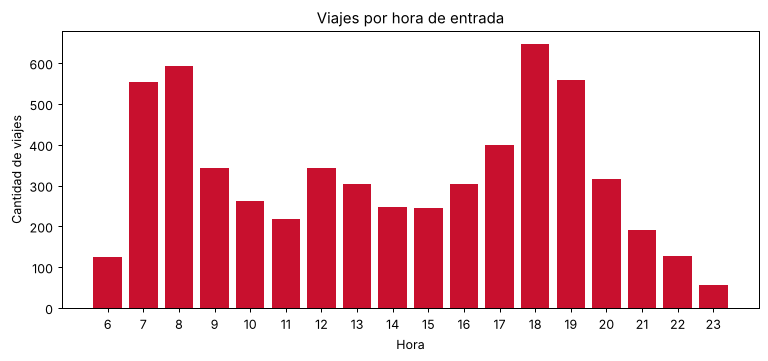

In [ ]:
"""COMPLETAR"""

## 3.5 Estadísticas básicas con NumPy 🔢

Extrae `duracion_min` como *array* con `.to_numpy()` y calcula su **promedio**, **mediana**, **mínimo** y **máximo**. Con `np.argmax` encuentra la posición del viaje más largo y muéstralo con `.iloc`.

> ¿Ves algo raro en el mínimo y el máximo? ¿Puede un viaje durar minutos negativos?

In [ ]:
"""COMPLETAR"""

Promedio: 11.57 min
Mediana:  10.30 min
Mínimo:   -14.60 min
Máximo:   313.50 min

Viaje más largo:
id_viaje                    V03972
fecha                   2026-10-22
hora                         08:44
estacion_origen     Plaza de Armas
estacion_destino        Los Héroes
tipo_tarjeta                Adulto
tarifa                       870.0
duracion_min                 313.5
satisfaccion                   5.0
hora_num                         8
horario                      Punta
Name: 3971, dtype: object


## 3.6 Detectar datos raros con comparaciones 🚨

En una red de 14 estaciones nadie demora más de **2 horas** en un viaje. Hay errores del lector (duraciones **negativas o cero**) y personas que salieron sin validar (duraciones **mayores a 120 minutos**).

1. Crea las máscaras booleanas `negativos` (duración `<= 0`) y `muy_largos` (duración `> 120`).
2. Usa `np.sum` para contar cuántos `True` tiene cada una.
3. Combínalas con `|` en una máscara `raros` y crea `viajes_ok` con las filas que **no** son raras (`~`).
4. Recalcula el promedio y la mediana. ¿Cuál de las dos cambió más? ¿Por qué?

In [ ]:
"""COMPLETAR"""

Duraciones <= 0:    14
Duraciones > 120:   29
Total de datos raros: 43

Antes   -> promedio: 11.57, mediana: 10.30
Después -> promedio: 10.56, mediana: 10.30


## 3.7 Operaciones entre arrays

Usando solo `viajes_ok`:

1. Crea `duracion_horas` dividiendo las duraciones por `60` (operación con escalar).
2. Crea `pesos_por_minuto` dividiendo el *array* de tarifas por el de duraciones (operación entre *arrays*). ¿Cuánto se paga en promedio por minuto de viaje?
3. ¿Qué tipo de tarjeta tiene el viaje con el **mayor** costo por minuto? (pista: `np.argmax` + `.iloc`)
4. ¿Cuántos viajes duran **más de 15 minutos**? Usa una comparación y `np.sum`.

In [ ]:
"""COMPLETAR"""

Duración en horas (primeros 5): [0.155 0.397 0.163 0.185 0.128]
Promedio pagado por minuto: $73.5

Mayor costo por minuto: $395.0 (Adulto, 2.0 min)
Viajes de más de 15 minutos: 865


## `BONUS` 3.8 Integración: grafos + datos 🔗

¿Los viajes que pasan por más estaciones duran más? Usa `ruta_mas_corta` de la Parte 2A para crear la columna `n_tramos` en `viajes_ok` (cantidad de tramos entre origen y destino).

- Hay solo $14 \times 13$ pares posibles de estaciones: calcula el BFS **una vez por par** y guárdalo en un diccionario, en vez de 6.000 veces.
- Agrupa por `n_tramos` y calcula la duración promedio. Grafica el resultado con barras.

n_tramos
1     6.7
2     9.0
3    11.4
4    13.9
5    16.3
6    18.8
Name: duracion_min, dtype: float64


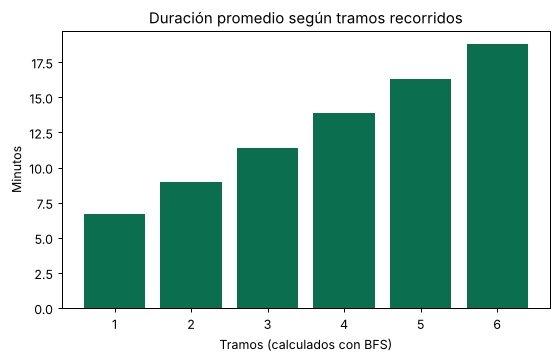

In [ ]:
"""COMPLETAR"""

---
## 🧭 Resumen: ¿qué herramienta uso?

| Quiero... | Herramienta | Dónde lo usamos |
|---|---|---|
| Validar que un texto **completo** cumpla un formato | `re.fullmatch` + grupos nombrados | 1.1 Validaciones de torniquetes |
| Encontrar **todas** las apariciones de un patrón | `re.findall` | 1.2 Contar líneas de metro |
| Reemplazar partes de un texto | `re.sub` (con `\1` para reusar un grupo) | 1.2 Anonimizar tarjetas |
| Saber si hay arista entre dos vértices rápidamente | Matriz de adyacencia | 2A Red de metro |
| Modelar objetos conectados entre sí | Estructura nodal (`Nodo.vecinos`) | 2B Laberinto |
| Saber **a qué nodos puedo llegar** / si existe un camino | DFS (stack o recursión) + visitados | 2.2 y 2.5 |
| Encontrar el camino con **menos pasos** | BFS (cola) + diccionario de `padres` | 2.3 y 2.6 |
| Cargar y explorar una tabla de datos | `pd.read_csv`, `.info()`, `.head()` | 3.1 |
| Filtrar filas / crear columnas / agrupar | `df[cond]`, `df["nueva"] = ...`, `.groupby` | 3.2 – 3.4 |
| Hacer cálculos sobre muchos números a la vez | *Arrays* de NumPy (`np.mean`, `np.sum`, `a / b`, ...) | 3.5 – 3.7 |
| Detectar o descartar datos inválidos | Máscaras booleanas (`>`, `&`, `\|`, `~`) | 3.6 |

## ✅ ¡Misión completada!

DCCMetro ya puede leer sus registros, calcular rutas aunque cierren estaciones, rescatar ayudantes perdidos y entender cómo viajan sus pasajeros. 🚇

# `¡MUCHO ÉXITO EN LO QUE QUEDA DEL SEMESTRE!` ❤️